# C1_05_Dense_vs_GRU
- X = X_flat_c1_v2.npy
- Y = y_labels_c1_v2.csv
- Built by Garmin_C1_DataBuild

### Dense networks vs GRU, with the previous window as input

C1_04_Input_Ablation found that adding the window just before the current one lifted the Simple DNN from 0.579 to 0.593. This notebook takes that input (`prev1`) and compares the two model families:

1. **Dense sweep** on `prev1`: four sizes, 3 seeds each. The simplest network within 0.003 of the best is chosen.
   - 16-8 (dropout 0.2)
   - 32-16 (dropout 0.2)
   - 64-32 (dropout 0.3)
   - 128-64-32 (dropout 0.3)
2. **GRU** on `prev1`: 3 layers of 64 units (GRU 64×3, the best model from the architecture sweep). The previous and current windows are joined into one 60-step sequence, earlier window first. One seed.

Every model uses the same windows as C1_04_Input_Ablation: those with both earlier windows available (`COMMON_LAGS = [1, 2]`). Scalers are fitted on the TRAIN windows only, and the test set is never built.

Each finished run is saved to `RESULTS_DIR`, and re-running skips the ones already done.

## 1. Setup and configuration

In [5]:
import gc
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

import tensorflow as tf
from tensorflow import keras

FRESH_START = False         # True = ignore any saved results and re-run everything

DATA_DIR = Path(r"C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed")
X_FLAT_PATH = DATA_DIR / "X_flat_c1_v2.npy"
Y_LABELS_PATH = DATA_DIR / "y_labels_c1_v2.csv"
RESULTS_DIR = DATA_DIR / "c1_context_final_2026-10-04"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = RESULTS_DIR / "results.csv"

WINDOW_SECONDS = 30
SEQ_COLS = 120               # first 120 columns of X_flat: HR, speed, cadence, temperature (30 each); column 120 = distance
COMMON_LAGS = [1, 2]         # windows must have both earlier windows 
CONTEXT_LAG = 1              # the earlier window added as input (1 = the window just before)

# --- Dense DNN sweep ---
DENSE_CONFIGS = {            # name: (hidden layer sizes, dropout). Dropout follows every hidden layer except the last.
    "16-8":      ([16, 8], 0.2),          # the Simple DNN from C1_04_Input_Ablation
    "32-16":     ([32, 16], 0.2),
    "64-32":     ([64, 32], 0.3),
    "128-64-32": ([128, 64, 32], 0.3),
}
DENSE_SEEDS = [42, 7, 123]
DENSE_BATCH = 256
DENSE_EPOCHS = 40
DENSE_PATIENCE = 5
DENSE_TIE_MARGIN = 0.003     # pick the simplest network within this much of the best mean accuracy

# --- GRU (settings identical to the architecture sweep, except the longer sequence) ---
GRU_NAME = "GRU 64x3 (V3)"
GRU_CONFIGS = {
    "GRU 64x3 (V3)":        dict(arch="gru", units=64, layers=3, dropout=0.3, lr=1e-3)
    #"GRU 32x2 (reference)": dict(arch="gru", units=32, layers=2, dropout=0.3, lr=1e-3),
}
GRU_SEEDS = [42]
GRU_BATCH = 64
GRU_MAX_EPOCHS = 60
GRU_PATIENCE = 8

REFERENCE = {
    "Dense 16-8, current window only (context test)": 0.579,
    "Dense 16-8, + previous window (context test)": 0.593,
    "GRU 64x3, current window only (architecture sweep, all windows)": 0.594,
}


## 2. Load data and build the common window set

Each window's earlier windows are found by matching `(file_path, start_s - 30 × lag)`. The first windows of each run have no earlier window, so they are left out. Every model is scored on the same windows, those that have all the earlier windows. The code checks that each earlier window comes from the same file and exactly the expected time before.


In [6]:
X_flat = np.load(X_FLAT_PATH).astype("float32")
y_df = pd.read_csv(Y_LABELS_PATH, parse_dates=["date"])
assert len(X_flat) == len(y_df), "X and Y row counts differ"
y_df["start_s"] = y_df["start_s"].astype(int)
print(f"X_flat {X_flat.shape}, {len(y_df)} labelled windows")

assert CONTEXT_LAG in COMMON_LAGS, "CONTEXT_LAG must be one of COMMON_LAGS"

row_lookup = pd.Series(np.arange(len(y_df)), index=pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"]]))
assert row_lookup.index.is_unique, "duplicate (file_path, start_s) keys"

lag_rows = {}
for lag in COMMON_LAGS:
    keys = pd.MultiIndex.from_arrays([y_df["file_path"], y_df["start_s"] - WINDOW_SECONDS * lag])
    lag_rows[lag] = row_lookup.reindex(keys).to_numpy()          # NaN where that earlier window does not exist

common = np.ones(len(y_df), dtype=bool)
for lag in COMMON_LAGS:
    common &= ~np.isnan(lag_rows[lag])
print(f"Windows with every earlier window available: {int(common.sum())} of {len(y_df)} ({100 * common.mean():.1f}%)")

for lag in COMMON_LAGS:
    r = lag_rows[lag][common].astype(int)
    assert (y_df["file_path"].to_numpy()[r] == y_df["file_path"].to_numpy()[common]).all(), "earlier window from a different file"
    assert (y_df["start_s"].to_numpy()[r] == y_df["start_s"].to_numpy()[common] - WINDOW_SECONDS * lag).all(), "earlier window at the wrong time"
print("OK: every earlier window is from the same file and exactly the expected time before.")

classes = np.array(sorted(y_df["c1_target"].unique()))
class_to_int = {c: i for i, c in enumerate(classes)}
n_classes = len(classes)
y_all = np.array([class_to_int[c] for c in y_df["c1_target"]])
print("Classes:", {str(c): i for c, i in class_to_int.items()})


X_flat (197341, 121), 197341 labelled windows
Windows with every earlier window available: 193591 of 197341 (98.1%)
OK: every earlier window is from the same file and exactly the expected time before.
Classes: {'Base': 0, 'Declining': 1, 'Improving': 2, 'Recovery': 3}


## 3. Split by run

The split is the same as in the baselines. The test runs are set aside and never built.

In [7]:
run_idx_all = y_df["run_idx"].to_numpy()
unique_runs = np.unique(run_idx_all)
train_runs, held_out_runs = train_test_split(unique_runs, test_size=0.2, random_state=42)
trainval_idx = np.where(np.isin(run_idx_all, train_runs))[0]
trainval_run_idx = run_idx_all[trainval_idx]
fit_runs, val_runs = train_test_split(np.unique(trainval_run_idx), test_size=0.15, random_state=42)

fit_idx = trainval_idx[np.isin(trainval_run_idx, fit_runs) & common[trainval_idx]]
val_idx = trainval_idx[np.isin(trainval_run_idx, val_runs) & common[trainval_idx]]

y_fit, y_val = y_all[fit_idx], y_all[val_idx]
print(f"Fit: {len(fit_idx)} windows | Val: {len(val_idx)} windows from {len(val_runs)} runs (test runs excluded, never built)")

np.save(RESULTS_DIR / "val_idx.npy", val_idx)      # saved so a later per-transition analysis can reuse the predictions

majority = np.bincount(y_fit, minlength=n_classes).argmax()
print(f"Naive (always '{classes[majority]}') validation accuracy: {(y_val == majority).mean():.3f}")

# Fixed subsample of FIT windows to measure train accuracy in inference mode (dropout off)
fit_sub_pos = np.random.default_rng(0).choice(len(fit_idx), size=min(20000, len(fit_idx)), replace=False)
y_fit_sub = y_fit[fit_sub_pos]


Fit: 130416 windows | Val: 24095 windows from 225 runs (test runs excluded, never built)
Naive (always 'Base') validation accuracy: 0.395


## 4. Helpers, features and results log

In [8]:
def safe(text):
    return re.sub(r"[^A-Za-z0-9_.-]+", "_", text)

def make_id(stage, name, seed):
    return f"{stage}|{name}|seed{seed}"

if RESULTS_CSV.exists() and not FRESH_START:
    results_df = pd.read_csv(RESULTS_CSV)
    print(f"Loaded {len(results_df)} saved results from {RESULTS_CSV}")
else:
    results_df = pd.DataFrame()

RECALL_COLS = [f"recall_{c}" for c in classes]


def already_done(run_id):
    return (not results_df.empty) and run_id in set(results_df["run_id"])


def record_run(stage, name, seed, model_type, input_set, model, history, X_val_in, X_fit_sub_in, minutes):
    """Score a trained model on the validation set, save predictions + loss history, append to the log."""
    global results_df
    run_id = make_id(stage, name, seed)
    pred = model.predict(X_val_in, batch_size=1024, verbose=0).argmax(axis=1)     # best-epoch weights are restored
    val_acc = accuracy_score(y_val, pred)
    recalls = recall_score(y_val, pred, average=None, labels=np.arange(n_classes), zero_division=0)
    _, fit_acc = model.evaluate(X_fit_sub_in, y_fit_sub, batch_size=1024, verbose=0)
    val_losses = history.history["val_loss"]
    row = {
        "run_id": run_id, "stage": stage, "name": name, "seed": seed, "model_type": model_type, "input_set": input_set,
        "params": int(model.count_params()), "best_epoch": int(np.argmin(val_losses)) + 1, "epochs_run": len(val_losses),
        "val_acc": float(val_acc), "macro_f1": float(f1_score(y_val, pred, average="macro")),
        "val_loss": float(min(val_losses)), "fit_acc_eval": float(fit_acc), "gap_acc": float(fit_acc - val_acc),
        "minutes": float(minutes),
    }
    for cls, r in zip(classes, recalls):
        row[f"recall_{cls}"] = float(r)
    np.save(RESULTS_DIR / f"pred_{safe(run_id)}.npy", pred)
    with open(RESULTS_DIR / f"hist_{safe(run_id)}.json", "w") as f:
        json.dump({k: [float(v) for v in vals] for k, vals in history.history.items()}, f)
    results_df = pd.concat([results_df, pd.DataFrame([row])], ignore_index=True)
    results_df.to_csv(RESULTS_CSV, index=False)
    print(f"-> {run_id}: val_acc {val_acc:.3f} | macro-F1 {row['macro_f1']:.3f} | train(eval) {fit_acc:.3f} | "
          f"gap {fit_acc - val_acc:+.3f} | best epoch {row['best_epoch']} | {minutes:.1f} min", flush=True)


# ---- Dense features: current window (121 cols incl. distance) + the earlier window's 120 sequence columns ----
def build_dense_features(idx):
    parts = [X_flat[idx], X_flat[lag_rows[CONTEXT_LAG][idx].astype(int), :SEQ_COLS]]
    return np.concatenate(parts, axis=1)

Xf_raw, Xv_raw = build_dense_features(fit_idx), build_dense_features(val_idx)
dense_scaler = StandardScaler().fit(Xf_raw)                                    # fit windows only
X_fit_dense = dense_scaler.transform(Xf_raw).astype("float32")
X_val_dense = dense_scaler.transform(Xv_raw).astype("float32")
del Xf_raw, Xv_raw
gc.collect()
print(f"Dense input: {X_fit_dense.shape[1]} features (121 current window + 120 from the earlier window)")


# ---- GRU sequences: earlier window first, then the current window, 4 channels ----
def make_sequence(idx, with_context):
    def block(rows):
        return np.stack([X_flat[rows, 0:30], X_flat[rows, 30:60], X_flat[rows, 60:90], X_flat[rows, 90:120]], axis=-1)
    parts = []
    if with_context:
        parts.append(block(lag_rows[CONTEXT_LAG][idx].astype(int)))            # earlier window (older time steps first)
    parts.append(block(idx))                                                   # current window
    return np.concatenate(parts, axis=1)                                       # (n, 30 or 60, 4)


def scaled_sequences(with_context):
    S_fit, S_val = make_sequence(fit_idx, with_context), make_sequence(val_idx, with_context)
    c = S_fit.shape[2]
    sc = StandardScaler().fit(S_fit.reshape(-1, c))                            # per channel, fit windows only
    f = sc.transform(S_fit.reshape(-1, c)).reshape(S_fit.shape).astype("float32")
    v = sc.transform(S_val.reshape(-1, c)).reshape(S_val.shape).astype("float32")
    return f, v


Loaded 13 saved results from C:\dev\UoW\DATAX504\Final Assignment\garmin_data\Processed\c1_context_final_2026-10-04\results.csv
Dense input: 241 features (121 current window + 120 from the earlier window)


## 5. Dense sweep on `prev1`

Four dense networks (16-8, 32-16, 64-32, 128-64-32), each trained on 3 seeds with the same settings as C1_04_Input_Ablation: batch 256, up to 40 epochs, early stopping (patience 5). 
The `16-8` network is the Simple DNN from that notebook, so its result can be compared directly with the 0.593 there.


In [9]:
def build_dense(n_features, hidden, dropout):
    layers = [keras.layers.Input(shape=(n_features,))]
    for i, units in enumerate(hidden):
        layers.append(keras.layers.Dense(units, activation="relu"))
        if i < len(hidden) - 1:
            layers.append(keras.layers.Dropout(dropout))
    layers.append(keras.layers.Dense(n_classes, activation="softmax"))
    model = keras.Sequential(layers)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


for name, (hidden, dropout) in DENSE_CONFIGS.items():
    for seed in DENSE_SEEDS:
        run_id = make_id("dense", name, seed)
        if already_done(run_id):
            print(f"[skip] {run_id}")
            continue
        keras.utils.set_random_seed(seed)
        model = build_dense(X_fit_dense.shape[1], hidden, dropout)
        t0 = time.time()
        history = model.fit(
            X_fit_dense, y_fit, validation_data=(X_val_dense, y_val),
            epochs=DENSE_EPOCHS, batch_size=DENSE_BATCH, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(patience=DENSE_PATIENCE, restore_best_weights=True)],
        )
        record_run("dense", name, seed, "dense", "prev1", model, history, X_val_dense, X_fit_dense[fit_sub_pos], (time.time() - t0) / 60)
        keras.backend.clear_session()

dense_rows = results_df[results_df["stage"] == "dense"]
dense_agg = dense_rows.groupby("name").agg(
    params=("params", "first"),
    n_seeds=("val_acc", "size"),
    acc_mean=("val_acc", "mean"),
    acc_std=("val_acc", lambda s: s.std(ddof=1) if len(s) > 1 else np.nan),
    macro_f1=("macro_f1", "mean"),
    gap=("gap_acc", "mean"),
    **{c: (c, "mean") for c in RECALL_COLS},
).sort_values("acc_mean", ascending=False)
print("\nDense DNN with the previous window, by mean validation accuracy:")
print(dense_agg.to_string(float_format=lambda v: f"{v:.3f}"))

best_mean = dense_agg["acc_mean"].max()
within_margin = dense_agg[dense_agg["acc_mean"] >= best_mean - DENSE_TIE_MARGIN]
best_dense_name = within_margin["params"].idxmin()
print(f"\nBest mean: {best_mean:.3f}. Networks within {DENSE_TIE_MARGIN} of it: {list(within_margin.index)}")
print(f"Chosen dense network (simplest within the margin): {best_dense_name}  "
      f"({int(dense_agg.loc[best_dense_name, 'params'])} parameters, mean accuracy {dense_agg.loc[best_dense_name, 'acc_mean']:.3f})")
if "16-8" in dense_agg.index:
    print(f"Check: 16-8 mean {dense_agg.loc['16-8', 'acc_mean']:.3f} vs. 0.593 in the context test.")


[skip] dense|16-8|seed42
[skip] dense|16-8|seed7
[skip] dense|16-8|seed123
[skip] dense|32-16|seed42
[skip] dense|32-16|seed7
[skip] dense|32-16|seed123
[skip] dense|64-32|seed42
[skip] dense|64-32|seed7
[skip] dense|64-32|seed123
[skip] dense|128-64-32|seed42
[skip] dense|128-64-32|seed7
[skip] dense|128-64-32|seed123

Dense DNN with the previous window, by mean validation accuracy:
           params  n_seeds  acc_mean  acc_std  macro_f1    gap  recall_Base  recall_Declining  recall_Improving  recall_Recovery
name                                                                                                                            
64-32       17700        3     0.600    0.002     0.635  0.000        0.661             0.557             0.551            0.725
128-64-32   41444        3     0.599    0.002     0.631  0.001        0.696             0.516             0.546            0.733
32-16        8340        3     0.599    0.002     0.634  0.001        0.674             0.544    

## 6. GRU on `prev1`

The previous and current windows are joined into one 60-step sequence (earlier window first). The model is the GRU 64×3 from the architecture sweep, with the same settings as there: batch 64, dropout and recurrent dropout 0.3, up to 60 epochs, early stopping (patience 8). One seed.


In [5]:
def build_gru(timesteps, n_channels, arch, units, layers, dropout, lr):
    Layer = keras.layers.GRU if arch == "gru" else keras.layers.LSTM
    inputs = keras.layers.Input(shape=(timesteps, n_channels))
    x = inputs
    for i in range(layers):
        x = Layer(units, recurrent_dropout=dropout, return_sequences=(i < layers - 1))(x)
    x = keras.layers.Dropout(dropout)(x)
    outputs = keras.layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model


def run_gru(with_context):
    input_set = "prev1" if with_context else "none"
    stage = "gru_prev1" if with_context else "gru_none"
    cfg = GRU_CONFIGS[GRU_NAME]
    todo = [s for s in GRU_SEEDS if not already_done(make_id(stage, GRU_NAME, s))]
    for s in GRU_SEEDS:
        if s not in todo:
            print(f"[skip] {make_id(stage, GRU_NAME, s)}")
    if not todo:
        return
    S_fit, S_val = scaled_sequences(with_context)
    print(f"{GRU_NAME}, input {input_set}: sequences {S_fit.shape[1]} steps x {S_fit.shape[2]} channels")
    for seed in todo:
        keras.utils.set_random_seed(seed)
        model = build_gru(S_fit.shape[1], S_fit.shape[2], **cfg)
        t0 = time.time()
        history = model.fit(
            S_fit, y_fit, validation_data=(S_val, y_val),
            epochs=GRU_MAX_EPOCHS, batch_size=GRU_BATCH, verbose=2,
            callbacks=[keras.callbacks.EarlyStopping(patience=GRU_PATIENCE, restore_best_weights=True)],
        )
        record_run(stage, GRU_NAME, seed, "gru", input_set, model, history, S_val, S_fit[fit_sub_pos], (time.time() - t0) / 60)
        keras.backend.clear_session()
    del S_fit, S_val
    gc.collect()


run_gru(with_context=True)


GRU 64x3 (V3), input prev1: sequences 60 steps x 4 channels
Epoch 1/60
2038/2038 - 440s - 216ms/step - accuracy: 0.5418 - loss: 0.9722 - val_accuracy: 0.5756 - val_loss: 0.9139
Epoch 2/60
2038/2038 - 461s - 226ms/step - accuracy: 0.5738 - loss: 0.9257 - val_accuracy: 0.5897 - val_loss: 0.8951
Epoch 3/60
2038/2038 - 480s - 235ms/step - accuracy: 0.5806 - loss: 0.9128 - val_accuracy: 0.5915 - val_loss: 0.8893
Epoch 4/60
2038/2038 - 415s - 203ms/step - accuracy: 0.5844 - loss: 0.9053 - val_accuracy: 0.5952 - val_loss: 0.8814
Epoch 5/60
2038/2038 - 448s - 220ms/step - accuracy: 0.5883 - loss: 0.9001 - val_accuracy: 0.6000 - val_loss: 0.8778
Epoch 6/60
2038/2038 - 417s - 205ms/step - accuracy: 0.5898 - loss: 0.8955 - val_accuracy: 0.6023 - val_loss: 0.8714
Epoch 7/60
2038/2038 - 493s - 242ms/step - accuracy: 0.5926 - loss: 0.8916 - val_accuracy: 0.6050 - val_loss: 0.8690
Epoch 8/60
2038/2038 - 506s - 248ms/step - accuracy: 0.5949 - loss: 0.8885 - val_accuracy: 0.6047 - val_loss: 0.8669
Epoc

## 7. Comparison: dense vs GRU (VAL windows)

The chosen dense network and the GRU, both with the previous window as input, scored on the VAL windows. The GRU is a single seed, so a gap under about 0.005 between the two should be read as a tie.

In [11]:
def summary_row(label, rows):
    if rows.empty:
        return None
    return {
        "model": label, "n_seeds": len(rows), "params": int(rows["params"].iloc[0]),
        "acc_mean": rows["val_acc"].mean(),
        "acc_std": rows["val_acc"].std(ddof=1) if len(rows) > 1 else np.nan,
        "macro_f1": rows["macro_f1"].mean(),
        **{c: rows[c].mean() for c in RECALL_COLS},
        "gap_acc": rows["gap_acc"].mean(),
    }

table = [
    summary_row(f"Dense {best_dense_name} + previous window", results_df[(results_df["stage"] == "dense") & (results_df["name"] == best_dense_name)]),
    summary_row(f"{GRU_NAME} + previous window", results_df[(results_df["stage"] == "gru_prev1") & (results_df["name"] == GRU_NAME)]),
]
comparison = pd.DataFrame([r for r in table if r is not None])
print(comparison.to_string(index=False, float_format=lambda v: f"{v:.3f}"))

print("\nReference points from earlier notebooks (different windows or settings, for orientation only):")
for k, v in REFERENCE.items():
    print(f"  {k}: {v:.3f}")


                          model  n_seeds  params  acc_mean  acc_std  macro_f1  recall_Base  recall_Declining  recall_Improving  recall_Recovery  gap_acc
  Dense 32-16 + previous window        3    8340     0.599    0.002     0.634        0.674             0.544             0.544            0.731    0.001
GRU 64x3 (V3) + previous window        1   63620     0.612      NaN     0.655        0.701             0.538             0.554            0.785    0.014

Reference points from earlier notebooks (different windows or settings, for orientation only):
  Dense 16-8, current window only (context test): 0.579
  Dense 16-8, + previous window (context test): 0.593
  GRU 64x3, current window only (architecture sweep, all windows): 0.594


## 8. Diagnostics: loss curves, confusion matrices and classification reports

Train and validation loss, the confusion matrix and the classification report on the VAL windows, for the chosen dense network (32-16, seed 42) and the GRU 64×3.

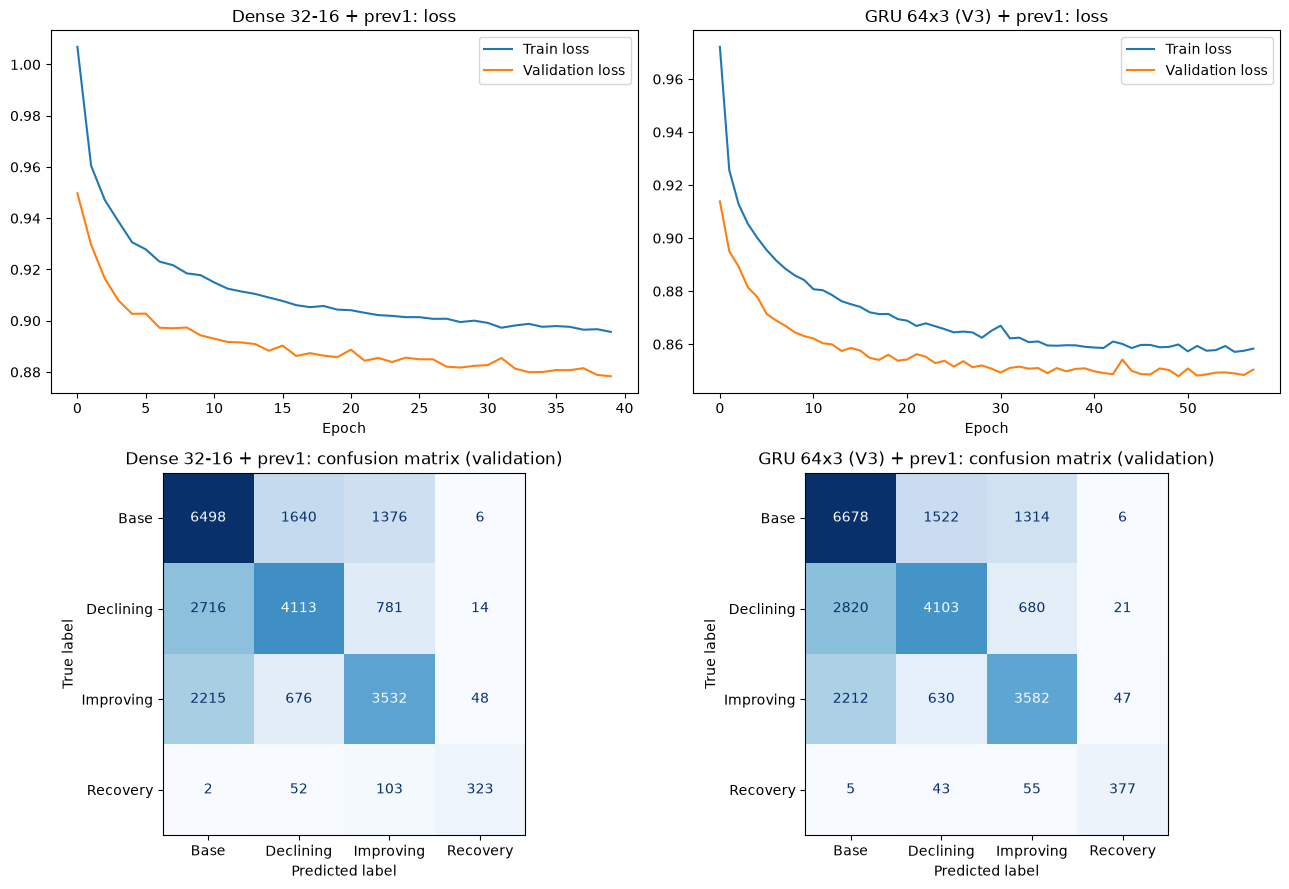


=== Dense 32-16 + prev1 (seed 42) ===
              precision    recall  f1-score   support

        Base       0.57      0.68      0.62      9520
   Declining       0.63      0.54      0.58      7624
   Improving       0.61      0.55      0.58      6471
    Recovery       0.83      0.67      0.74       480

    accuracy                           0.60     24095
   macro avg       0.66      0.61      0.63     24095
weighted avg       0.61      0.60      0.60     24095


=== GRU 64x3 (V3) + prev1 (seed 42) ===
              precision    recall  f1-score   support

        Base       0.57      0.70      0.63      9520
   Declining       0.65      0.54      0.59      7624
   Improving       0.64      0.55      0.59      6471
    Recovery       0.84      0.79      0.81       480

    accuracy                           0.61     24095
   macro avg       0.67      0.64      0.66     24095
weighted avg       0.62      0.61      0.61     24095



In [12]:
chosen = [("Dense " + best_dense_name + " + prev1", make_id("dense", best_dense_name, DENSE_SEEDS[0]))]
gru_id = make_id("gru_prev1", GRU_NAME, GRU_SEEDS[0])
if already_done(gru_id):
    chosen.append((GRU_NAME + " + prev1", gru_id))

fig, axes = plt.subplots(2, len(chosen), figsize=(6.5 * len(chosen), 9), squeeze=False)
for col, (label, run_id) in enumerate(chosen):
    with open(RESULTS_DIR / f"hist_{safe(run_id)}.json") as f:
        hist = json.load(f)
    axes[0, col].plot(hist["loss"], label="Train loss")
    axes[0, col].plot(hist["val_loss"], label="Validation loss")
    axes[0, col].set_title(f"{label}: loss")
    axes[0, col].set_xlabel("Epoch")
    axes[0, col].legend()

    pred = np.load(RESULTS_DIR / f"pred_{safe(run_id)}.npy")
    cm = confusion_matrix(y_val, pred, labels=np.arange(n_classes))
    ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes).plot(ax=axes[1, col], cmap="Blues", colorbar=False)
    axes[1, col].set_title(f"{label}: confusion matrix (validation)")
plt.tight_layout()
plt.show()

for label, run_id in chosen:
    pred = np.load(RESULTS_DIR / f"pred_{safe(run_id)}.npy")
    print(f"\n=== {label} (seed {run_id.split('seed')[-1]}) ===")
    print(classification_report(y_val, pred, labels=np.arange(n_classes), target_names=[str(c) for c in classes], zero_division=0))

